<a href="https://colab.research.google.com/github/peeyush211/ML-Lab/blob/main/Lab_8_DbSCAN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Lab 8**

**Aim - Perform Dbscan Clustering on sample dataset**

**Peeyush Agarwal 2427010184 AIM3130**

In [1]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

In [2]:
uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[filename]))

display(df.head())

Saving Mall_Customers.csv to Mall_Customers (1).csv


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
# Check dataset size, data types, missing values, and duplicates
print("Dataset shape:", df.shape)

df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

display(df.describe())

Dataset shape: (200, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Missing values:
CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate rows: 0


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [4]:
# Select income and spending score for clustering
features = ['Annual Income (k$)', 'Spending Score (1-100)']

# Remove duplicate records and rows missing the selected features
df_clean = df.drop_duplicates().copy()

for column in features:
    df_clean[column] = pd.to_numeric(df_clean[column], errors='coerce')

df_clean = df_clean.dropna(subset=features).copy()

X = df_clean[features]

print("Rows used for clustering:", len(X))
display(X.head())

Rows used for clustering: 200


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


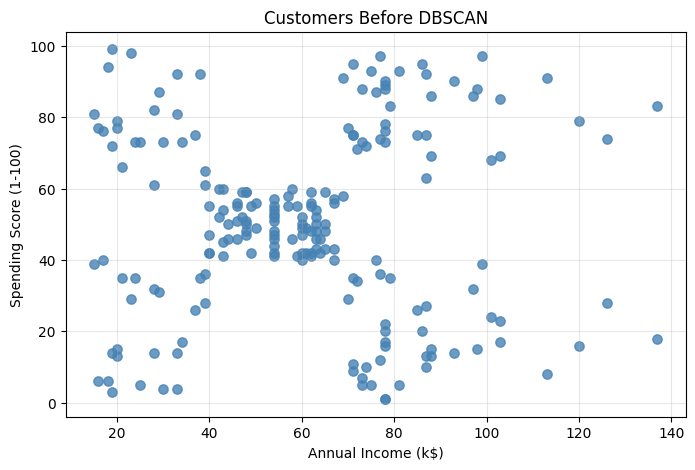

In [5]:
# Plot customers before applying DBSCAN
plt.figure(figsize=(8, 5))

plt.scatter(
    X['Annual Income (k$)'],
    X['Spending Score (1-100)'],
    color='steelblue',
    s=45,
    alpha=0.8
)

plt.title("Customers Before DBSCAN")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.grid(alpha=0.3)
plt.show()

In [6]:
# Standardize features because DBSCAN uses distances
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

display(pd.DataFrame(
    X_scaled,
    columns=features,
    index=X.index
).head())

,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


In [7]:
# Apply DBSCAN; eps is measured in the standardized feature space
dbscan = DBSCAN(eps=0.3, min_samples=5)

labels = dbscan.fit_predict(X_scaled)

df_clean['Cluster'] = labels

display(df_clean.head(10))

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,2
1,2,Male,21,15,81,0
2,3,Female,20,16,6,1
3,4,Female,23,16,77,0
4,5,Female,31,17,40,2
5,6,Female,22,17,76,0
6,7,Female,35,18,6,1
7,8,Female,23,18,94,-1
8,9,Male,64,19,3,1
9,10,Female,30,19,72,0


In [9]:
# Label -1 represents noise and is excluded from the cluster count
n_clusters = len(set(labels) - {-1})
n_noise = np.sum(labels == -1)

print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)
print(f"Noise percentage: {n_noise / len(labels) * 100:.2f}%")

print("\nCustomers in each cluster (-1 = noise):")
print(df_clean['Cluster'].value_counts().sort_index())

Number of clusters: 7
Number of noise points: 35
Noise percentage: 17.50%

Customers in each cluster (-1 = noise):
Cluster
-1    35
 0    12
 1     5
 2     7
 3    88
 4    30
 5    14
 6     9
Name: count, dtype: int64


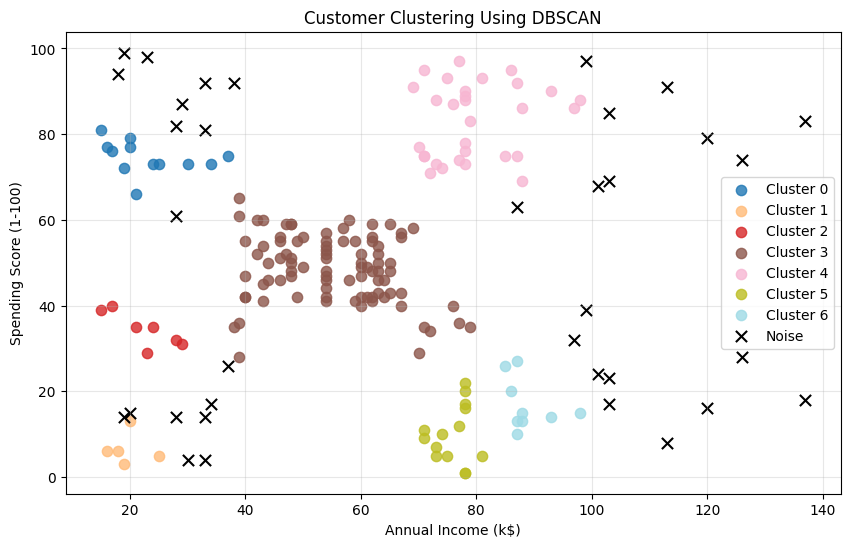

In [8]:
# Plot each cluster separately and mark noise with black crosses
plt.figure(figsize=(10, 6))

cluster_ids = sorted(set(labels) - {-1})
colors = plt.cm.tab20(np.linspace(0, 1, max(len(cluster_ids), 1)))

for cluster_id, color in zip(cluster_ids, colors):
    cluster_data = df_clean[df_clean['Cluster'] == cluster_id]

    plt.scatter(
        cluster_data['Annual Income (k$)'],
        cluster_data['Spending Score (1-100)'],
        color=color,
        label=f'Cluster {cluster_id}',
        s=55,
        alpha=0.8
    )

noise_data = df_clean[df_clean['Cluster'] == -1]

if not noise_data.empty:
    plt.scatter(
        noise_data['Annual Income (k$)'],
        noise_data['Spending Score (1-100)'],
        color='black',
        marker='x',
        label='Noise',
        s=65
    )

plt.title("Customer Clustering Using DBSCAN")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()